# 02 · Sanity review

Visual check of value ranges in `data/processed/climate_precip.parquet` (built by `python -m src.convert_to_parquet`).
The automated checks live in `python -m src.sanity_checks` → `outputs/tables/sanity_report.csv`; this notebook only looks at them.

All aggregation runs in DuckDB, so the full Parquet file is never loaded into pandas.

In [1]:
import sys
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.config import DATA_PROCESSED, OUT_TABLES, MODELS, UNITS, BASELINE, FUTURE_WINDOWS

VAR = "precip"
PQ = (DATA_PROCESSED / f"climate_{VAR}.parquet").as_posix()
SCENS = ["historical", "RCP45", "RCP85"]
# Fixed categorical order: a model keeps its colour in every plot (palette validated for CVD)
COLORS = dict(zip(MODELS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
UNIT = UNITS[VAR]

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "#8a8a85", "axes.labelcolor": "#3d3d3a", "xtick.color": "#5c5c57",
    "ytick.color": "#5c5c57", "axes.titleweight": "bold", "legend.frameon": False,
})
con = duckdb.connect()
pd.set_option("display.width", 200)

## 1. Sanity report

In [2]:
report = pd.read_csv(OUT_TABLES / "sanity_report.csv")
print(report["status"].value_counts().to_string())
report[report["status"] != "PASS"]

status
PASS    164
WARN      2


,var,model,scen,check,value,expected,status,note
85,precip,HadGEM2-ES,RCP45,n_months,1127,1128,WARN,"1 month(s) missing, last = 2099-11"
157,precip,HadGEM2-ES,RCP45,window_end,431,432,WARN,2064-2099: 1 month(s) missing


## 2. Value ranges per model and scenario

The whiskers run from min to max; the box shows Q1–median–Q3. Everything should sit between 0 and the plausible maximum (1500 mm/month).

In [3]:
q = con.execute(f'''
    SELECT model, scen, min(value) AS whislo, quantile_cont(value, 0.25) AS q1,
           median(value) AS med, quantile_cont(value, 0.75) AS q3, max(value) AS whishi,
           avg(value) AS mean
    FROM '{PQ}' GROUP BY ALL
''').df()
q.pivot(index="model", columns="scen", values=["whislo", "med", "whishi"]).round(1)

whislo                    med                  whishi                  
scen        RCP45 RCP85 historical RCP45 RCP85 historical  RCP45  RCP85 historical
model                                                                             
BESM          0.0   0.0        0.0  50.4  42.9       55.7  563.6  548.9      472.1
CanESM2       0.0   0.0        0.0  64.7  58.7       57.5  540.9  564.0      520.3
HadGEM2-ES    0.0   0.0        0.0  52.7  48.8       57.1  676.2  623.5      523.0
MIROC5        0.0   0.0        0.0  48.2  49.9       44.3  476.3  630.2      501.9

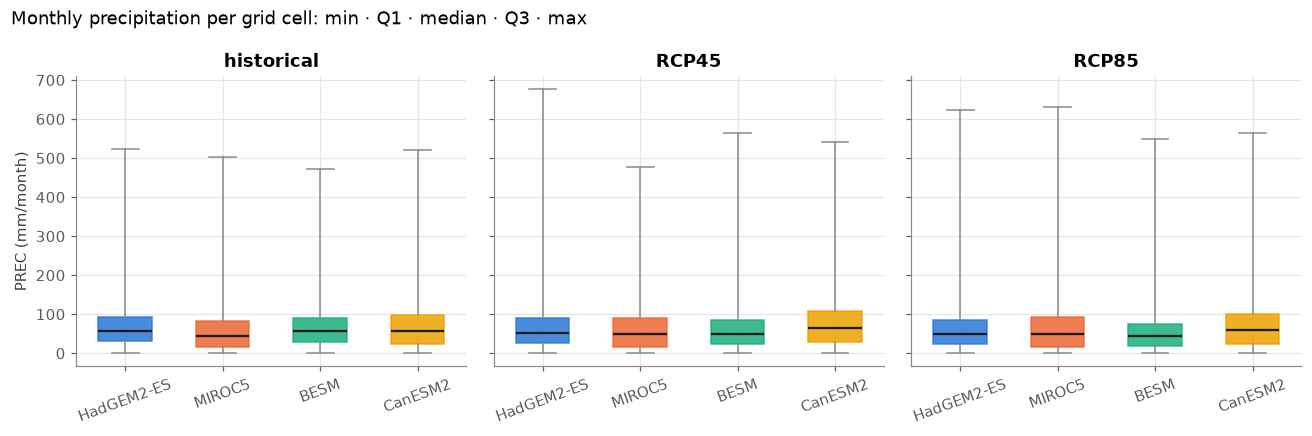

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for ax, scen in zip(axes, SCENS):
    sub = q[q["scen"] == scen].set_index("model").loc[MODELS]
    stats = [dict(label=m, **sub.loc[m, ["whislo", "q1", "med", "q3", "whishi"]].to_dict()) for m in MODELS]
    b = ax.bxp(stats, showfliers=False, patch_artist=True, widths=0.55,
               medianprops=dict(color="#1a1a19", linewidth=1.5),
               whiskerprops=dict(color="#8a8a85"), capprops=dict(color="#8a8a85"))
    for patch, m in zip(b["boxes"], MODELS):
        patch.set(facecolor=COLORS[m], edgecolor=COLORS[m], alpha=0.85)
    ax.set_title(scen)
    ax.tick_params(axis="x", rotation=20)
axes[0].set_ylabel(f"PREC ({UNIT})")
fig.suptitle("Monthly precipitation per grid cell: min · Q1 · median · Q3 · max", x=0.01, ha="left")
fig.tight_layout()

## 3. Seasonal cycle

The mean over all cells for each calendar month. Paraguay should be wet from October to March and dry from June to August, in every model.

month                     1     2      3      4     5     6     7     8     9      10     11     12
scen       model                                                                                   
RCP45      BESM         67.0  63.0   52.0   59.0  71.0  43.0  32.0  27.0  34.0   75.0  116.0   91.0
           CanESM2     102.0  89.0  101.0  102.0  70.0  30.0  25.0  30.0  49.0   99.0  117.0  102.0
           HadGEM2-ES   56.0  50.0   56.0   66.0  65.0  62.0  54.0  58.0  71.0  112.0   85.0   66.0
           MIROC5      102.0  84.0   71.0   46.0  32.0  21.0  19.0  26.0  36.0   74.0  102.0  111.0
RCP85      BESM         62.0  51.0   44.0   49.0  47.0  38.0  31.0  26.0  28.0   75.0  112.0   86.0
           CanESM2      89.0  78.0   95.0   92.0  71.0  29.0  21.0  25.0  39.0   92.0  112.0   99.0
           HadGEM2-ES   65.0  55.0   51.0   54.0  49.0  49.0  43.0  50.0  71.0  111.0   92.0   68.0
           MIROC5      103.0  85.0   75.0   52.0  31.0  18.0  18.0  23.0  36.0   82.0  110.0  122.0
historical BESM         76.0  70.0   68.0   63.0  57.0  33.0  42.0  47.0  51.0   87.0  103.0   91.0
           CanESM2      95.0  83.0   91.0   80.0  58.0  29.0  21.0  27.0  48.0   90.0  112.0  100.0
           HadGEM2-ES   70.0  63.0   62.0   61.0  58.0  63.0  51.0  51.0  74.0   91.0   90.0   80.0
           MIROC5      107.0  77.0   64.0   41.0  29.0  23.0  19.0  23.0  33.0   65.0   87.0  106.0

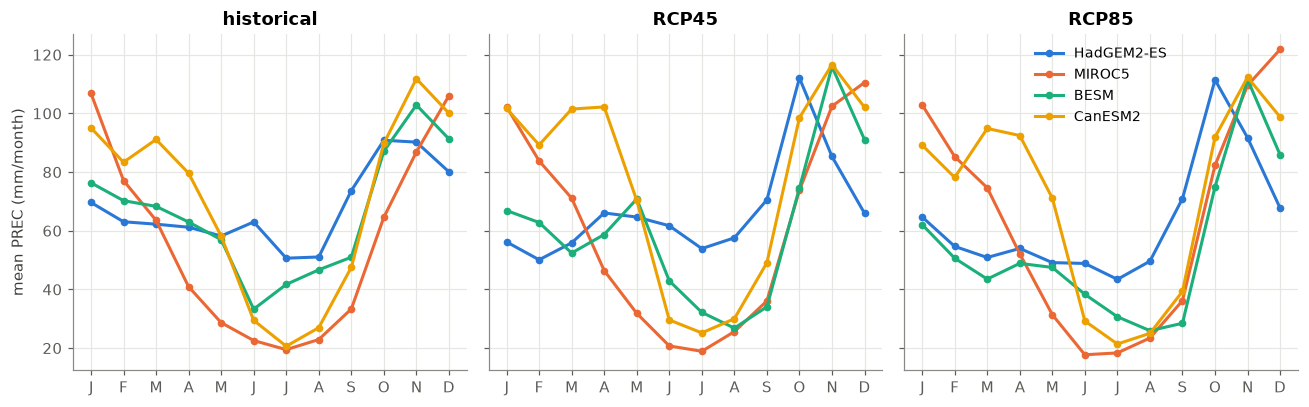

In [5]:
clim = con.execute(f"SELECT model, scen, month, avg(value) AS v FROM '{PQ}' GROUP BY ALL").df()
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, scen in zip(axes, SCENS):
    for m in MODELS:
        s = clim[(clim["scen"] == scen) & (clim["model"] == m)].sort_values("month")
        ax.plot(s["month"], s["v"], color=COLORS[m], lw=2, marker="o", ms=4, label=m)
    ax.set_title(scen)
    ax.set_xticks(range(1, 13), list("JFMAMJJASOND"))
axes[0].set_ylabel(f"mean PREC ({UNIT})")
axes[-1].legend(loc="upper center", fontsize=9)
fig.tight_layout()
clim.pivot_table(index=["scen", "model"], columns="month", values="v").round(0)

## 4. Annual totals over time

Annual totals are the sum of the 12 monthly values (mm/month), averaged over all cells. The historical run continues into each RCP.
Shaded bands mark the analysis windows: the baseline (1976–2005) and the projection terms mid (2027–2063) and end (2064–2099). 2006–2026 is plotted but not analysed.
The final year (2099) is dropped for HadGEM2-ES RCP45 because December is missing, so its 11-month total would look like a false drop.

min   mean     max
model      scen                            
BESM       RCP45       489.0  729.0  1010.0
           RCP85       369.0  648.0   959.0
           historical  601.0  789.0  1155.0
CanESM2    RCP45       667.0  916.0  1307.0
           RCP85       453.0  844.0  1354.0
           historical  559.0  834.0  1066.0
HadGEM2-ES RCP45       310.0  799.0  1337.0
           RCP85       346.0  757.0  1265.0
           historical  469.0  814.0  1168.0
MIROC5     RCP45       482.0  724.0  1021.0
           RCP85       365.0  756.0  1232.0
           historical  465.0  673.0  1212.0

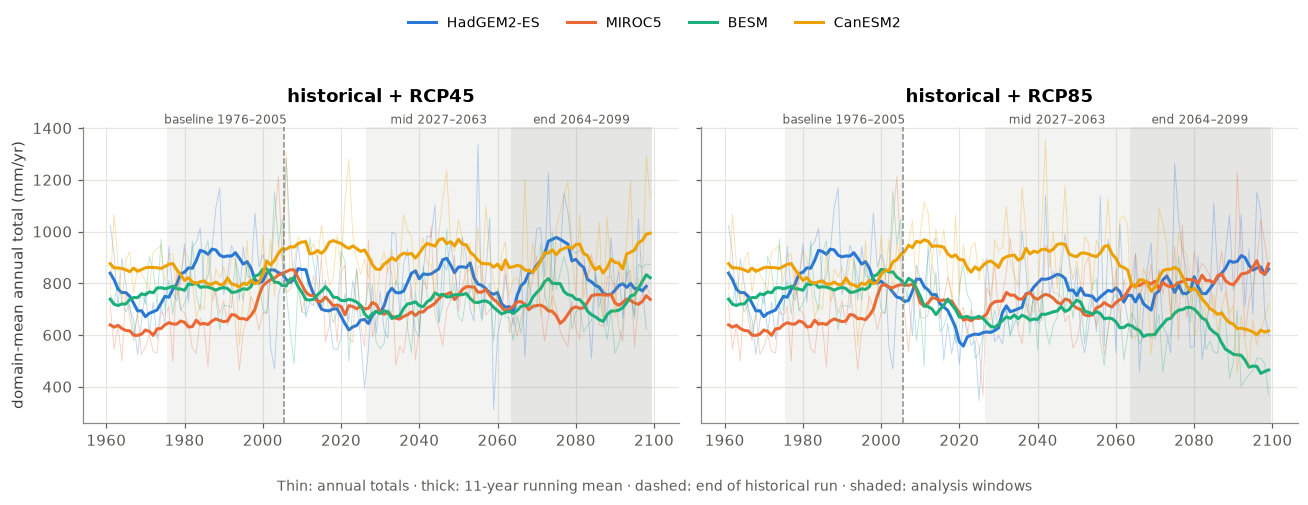

In [6]:
ann = con.execute(f'''
    SELECT model, scen, year, sum(value) / count(DISTINCT (lat, lon)) AS annual_mm,
           count(DISTINCT month) AS n_months
    FROM '{PQ}' GROUP BY ALL
''').df()
ann = ann[ann["n_months"] == 12]   # drop incomplete years

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, rcp in zip(axes, ["RCP45", "RCP85"]):
    for m in MODELS:
        s = ann[(ann["model"] == m) & ann["scen"].isin(["historical", rcp])].sort_values("year")
        ax.plot(s["year"], s["annual_mm"], color=COLORS[m], lw=0.6, alpha=0.3)
        ax.plot(s["year"], s["annual_mm"].rolling(11, center=True, min_periods=6).mean(),
                color=COLORS[m], lw=2, label=m)
    for name, (y0, y1) in {"baseline": BASELINE, **FUTURE_WINDOWS}.items():
        ax.axvspan(y0 - 0.5, y1 + 0.5, color="#8a8a85", alpha={"baseline": 0.10, "mid": 0.10, "end": 0.22}[name], lw=0)
        ax.text((y0 + y1) / 2, 1.0, f"{name} {y0}–{y1}", transform=ax.get_xaxis_transform(),
                ha="center", va="bottom", fontsize=8, color="#5c5c57")
    ax.axvline(2005.5, color="#8a8a85", lw=1, ls="--")
    ax.set_title(f"historical + {rcp}", pad=16)
axes[0].set_ylabel("domain-mean annual total (mm/yr)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, fontsize=9, bbox_to_anchor=(0.5, 1.02))
fig.suptitle("Thin: annual totals · thick: 11-year running mean · dashed: end of historical run · shaded: analysis windows",
             y=-0.01, fontsize=9, color="#5c5c57")
fig.tight_layout(rect=(0, 0.02, 1, 0.94))
ann.groupby(["model", "scen"])["annual_mm"].agg(["min", "mean", "max"]).round(0)

## 5. Takeaways

- No nulls, negatives, duplicates or grid mismatches. The only flag is the known missing month, HadGEM2-ES RCP45 2099-12.
- Monthly values range from 0 to about 680 mm/month, well below the plausible maximum.
- BESM, CanESM2 and MIROC5 show a clear wet Oct–Mar / dry Jun–Aug cycle (about 20–35 mm/month in winter). **HadGEM2-ES has a much weaker dry season** (about 45–65 mm/month in Jun–Aug in every scenario), so its winter changes deserve caution.
- Year-to-year variability is large (domain means swing roughly 400–1,300 mm/yr), so trends should be judged on 30-year windows, not single years.
- The models differ in their mean level, so later steps should compare each model's future against **its own** historical baseline (1976–2005), for the mid (2027–2063) and end (2064–2099) terms.